# IMPORT AND LOAD DATA

In [1]:
# Load subject list and paths
import pandas as pd
import os
import numpy as np

In [2]:
SUBJS = np.sort(os.listdir('raw_data'))[1:]
SUBJS

array(['PRISM 001', 'PRISM 002', 'PRISM 125', 'PRISM 126', 'PRISM 127',
       'PRISM 128', 'PRISM 129', 'PRISM 130', 'PRISM 131', 'PRISM 132',
       'PRISM 133', 'PRISM 134'], dtype='<U9')

# ONE PATIENT EXAMPLE

In [3]:
SUBJS = [SUBJS[0]]

In [4]:
SUBJS

[np.str_('PRISM 001')]

In [5]:
paths_subj = "data/raw_data/PRISM " + SUBJS[0] + "/"

print(f"Loaded {len(SUBJS)} subjects: {SUBJS[0].tolist()}...")

Loaded 1 subjects: PRISM 001...


In [6]:
for SUBJ in SUBJS:
    if not os.path.exists('data'):
        os.mkdir('data')
    if not os.path.exists(f'data/{SUBJ}'):
        os.mkdir(f'data/{SUBJ}')
    if not os.path.exists(f'data/{SUBJ}/images'):
        os.mkdir(f'data/{SUBJ}/images')
    if not os.path.exists(f'data/{SUBJ}/features'):
        os.mkdir(f'data/{SUBJ}/features')
    if not os.path.exists(f'data/{SUBJ}/labels'):
        os.mkdir(f'data/{SUBJ}/labels')
    

# DICOM T2 to NIFTY T2

In [7]:
# DICOM -> NIfTI (T2) con geometria corretta usando SimpleITK (leggibile + robusto)
import os
from pathlib import Path
import SimpleITK as sitk

def dicom_series_to_nifti_sitk(dicom_dir: str, output_path: str, pick="largest") -> str:
    """
    Convert a DICOM series folder to NIfTI using SimpleITK/GDCM, preserving correct geometry:
      - Origin
      - Spacing
      - Direction

    pick:
      - "largest": choose the series with the most files (recommended if folder may contain multiple series)
      - "first": choose the first detected series (ok if folder contains only one series)
    """
    dicom_dir = str(dicom_dir)
    out_path = Path(output_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)

    reader = sitk.ImageSeriesReader()
    series_ids = reader.GetGDCMSeriesIDs(dicom_dir)
    if not series_ids:
        raise ValueError(f"No DICOM series found in: {dicom_dir}")

    if pick == "first":
        chosen = series_ids[0]
    elif pick == "largest":
        chosen = None
        best_n = -1
        for sid in series_ids:
            files = reader.GetGDCMSeriesFileNames(dicom_dir, sid)
            if len(files) > best_n:
                best_n = len(files)
                chosen = sid
    else:
        raise ValueError("pick must be 'largest' or 'first'")

    dicom_files = reader.GetGDCMSeriesFileNames(dicom_dir, chosen)
    reader.SetFileNames(dicom_files)

    img = reader.Execute()

    sitk.WriteImage(img, str(out_path), useCompression=True)

    # quick debug (geometry)
    print(f"   Found {len(dicom_files)} DICOM files (series={chosen})")
    print(f"   ✅ Saved: {out_path}")
    print(f"   ✅ Size: {img.GetSize()}")
    print(f"   ✅ Spacing: {img.GetSpacing()}")
    print(f"   ✅ Origin: {img.GetOrigin()}")
    # Direction is 3x3 flattened row-major
    print(f"   ✅ Direction: {img.GetDirection()}")

    return str(out_path)

# -----------------------------
# Process all subjects -> 0000.nii.gz
# -----------------------------
print("Creating 0000.nii.gz files with correct DICOM geometry (SimpleITK)...")
conversion_success = 0
conversion_errors = 0

for subj in SUBJS:
    try:
        base = Path(f"raw_data/{subj}")
        out = Path(f'data/{subj}/images')
        t2_dicom_dir = base / "T2"
        t2_output_path = out / "0001.nii.gz"

        if not t2_dicom_dir.exists():
            print(f"[{subj}] No T2 DICOM directory found: {t2_dicom_dir}")
            conversion_errors += 1
            continue

        print(f"[{subj}] Converting T2 DICOM → NIfTI...")

        dicom_series_to_nifti_sitk(
            dicom_dir=str(t2_dicom_dir),
            output_path=str(t2_output_path),
            pick="largest"  # <- cambia in "first" se sei sicuro che c'è una sola serie
        )

        conversion_success += 1
        print(f"[{subj}] ✅ T2.nii.gz created successfully")

    except Exception as e:
        print(f"[{subj}] ❌ ERROR: {e}")
        conversion_errors += 1

print("\n📊 T2 DICOM→NIfTI Conversion Summary:")
print(f"   ✅ Successful: {conversion_success}")
print(f"   ❌ Errors: {conversion_errors}")
print(f"   📁 Total processed: {len(SUBJS)}")

if conversion_success > 0:
    print("\n🎯 Now T2.nii.gz files have correct geometric information!")
    print("   Use these instead of the old T2.nii.gz files for mask generation.")


Creating 0000.nii.gz files with correct DICOM geometry (SimpleITK)...
[PRISM 001] Converting T2 DICOM → NIfTI...
   Found 27 DICOM files (series=1.3.6.1.4.1.18047.1.11.10029191740137137654)
   ✅ Saved: data\PRISM 001\images\0001.nii.gz
   ✅ Size: (320, 320, 27)
   ✅ Spacing: (0.625, 0.625, 3.3000000027168515)
   ✅ Origin: (-106.31977214897, -113.25768702547, -81.648023354238)
   ✅ Direction: (0.9984517586811356, 0.016611151048270083, 0.05308629999725942, -0.017639842306094146, 0.9996644644546308, 0.01896824899805953, -0.05275340320741024, -0.01987531553177989, 0.9984097607107758)
[PRISM 001] ✅ T2.nii.gz created successfully

📊 T2 DICOM→NIfTI Conversion Summary:
   ✅ Successful: 1
   ❌ Errors: 0
   📁 Total processed: 1

🎯 Now T2.nii.gz files have correct geometric information!
   Use these instead of the old T2.nii.gz files for mask generation.


# ADD GEOM INFORMATION TO T2 MASK

In [8]:
# Generate T2_mask_2026.nii.gz with correct geometry (HEADER FIX ONLY)
import os
import nibabel as nib
import numpy as np

print("🎭 Generating T2 masks with correct geometry (header-only)...")
print("=" * 50)

total_updated = 0
total_errors = 0
total_skipped = 0

for subj in SUBJS:
    try:
        base = f"raw_data/{subj}"
        out = f'data/{subj}'
        t2_new_path   = f"{out}/images/0001.nii.gz"
        mask_old_path = f"{base}/t2_mask.nii.gz"
        mask_new_path = f"{out}/labels/0001.nii.gz"

        # --- existence check ---
        if not os.path.exists(t2_new_path) or not os.path.exists(mask_old_path):
            total_skipped += 1
            continue

        # --- load ---
        t2_new   = nib.load(t2_new_path)
        mask_old = nib.load(mask_old_path)

        # --- CRITICAL SAFETY CHECK ---
        if t2_new.shape != mask_old.shape:
            raise ValueError(
                f"Shape mismatch: T2 {t2_new.shape} vs mask {mask_old.shape}"
            )

        # --- header-only fix ---
        mask_data = mask_old.get_fdata(dtype=np.float32)

        updated_mask = nib.Nifti1Image(
            mask_data,
            affine=t2_new.affine,
            header=t2_new.header.copy()
        )

        nib.save(updated_mask, mask_new_path)

        total_updated += 1
        print(f"[{subj}] ✅ t2_mask.nii.gz created")

    except Exception as e:
        print(f"[{subj}] ❌ ERROR: {e}")
        total_errors += 1

print("\n📊 T2 Mask Generation Summary:")
print(f"   ✅ Successfully created: {total_updated}")
print(f"   ⏭️  Skipped: {total_skipped}")
print(f"   ❌ Errors: {total_errors}")
print(f"   📁 Total processed: {len(SUBJS)}")


🎭 Generating T2 masks with correct geometry (header-only)...
[PRISM 001] ✅ t2_mask.nii.gz created

📊 T2 Mask Generation Summary:
   ✅ Successfully created: 1
   ⏭️  Skipped: 0
   ❌ Errors: 0
   📁 Total processed: 1


# PLOT CHECK

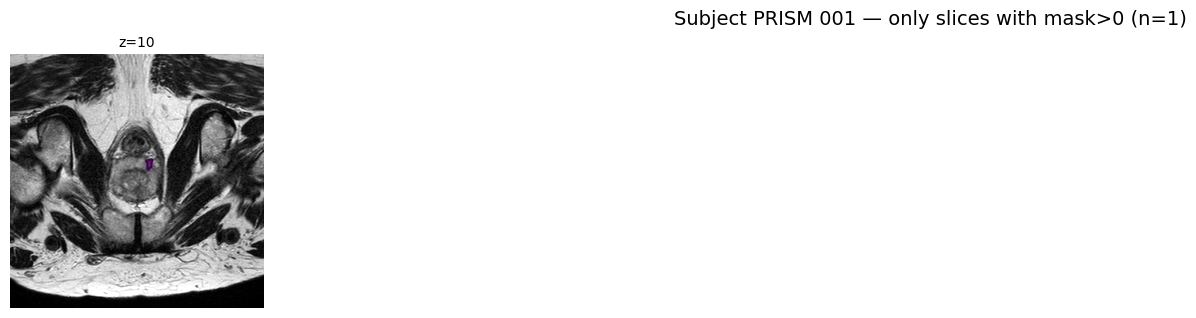

In [9]:
import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

def show_t2_with_mask_slices(
    subj,
    base_dir="data",
    t2_name="images/0001.nii.gz",
    mask_name="labels/0001.nii.gz",
    max_slices=24,          # limita quante slice mostrare (per non esplodere)
    cols=6,                 # colonne del grid
    overlay_mode="contour", # "contour" o "alpha"
    alpha=0.35              # usato se overlay_mode="alpha"
):
    base = os.path.join(base_dir, f"{subj}")
    t2_path   = os.path.join(base, t2_name)
    mask_path = os.path.join(base, mask_name)

    if not os.path.exists(t2_path) or not os.path.exists(mask_path):
        print(f"[{subj}] missing files: {t2_path} or {mask_path}")
        return

    t2 = nib.load(t2_path)
    m  = nib.load(mask_path)

    t2_data = t2.get_fdata()
    m_data  = m.get_fdata()

    if t2_data.shape != m_data.shape:
        print(f"[{subj}] SHAPE MISMATCH: T2 {t2_data.shape} vs mask {m_data.shape}")
        return

    # slice indices with any mask voxel > 0
    idx = np.where(np.any(m_data > 0, axis=(0, 1)))[0]
    if len(idx) == 0:
        print(f"[{subj}] no non-zero mask slices.")
        return

    # cap
    if len(idx) > max_slices:
        # prendi in modo uniforme su tutta la lesione
        pick = np.linspace(0, len(idx)-1, max_slices).round().astype(int)
        idx = idx[pick]

    n = len(idx)
    rows = int(np.ceil(n / cols))

    fig = plt.figure(figsize=(3.2*cols, 3.2*rows))
    fig.suptitle(f"Subject {subj} — only slices with mask>0 (n={n})", fontsize=14)

    for k, z in enumerate(idx, start=1):
        ax = fig.add_subplot(rows, cols, k)

        img = t2_data[:, :, z]
        mask = m_data[:, :, z]

        # robust contrast per slice (evita saturazione)
        p1, p99 = np.percentile(img[np.isfinite(img)], [1, 99])
        ax.imshow(img.T, cmap="gray", origin="lower", vmin=p1, vmax=p99)

        if overlay_mode == "contour":
            ax.contour(mask.T > 0, levels=[0.5], origin="lower", linewidths=1.5)
        elif overlay_mode == "alpha":
            ax.imshow((mask.T > 0).astype(float), origin="lower", alpha=alpha)
        else:
            raise ValueError("overlay_mode must be 'contour' or 'alpha'")

        ax.set_title(f"z={z}", fontsize=10)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

# ---- RUN: mostra per tutti i SUBJS (uno alla volta) ----
# Consiglio: prova prima con pochi
#for subj in SUBJS[40:41]:
    #show_t2_with_mask_slices_NEW(subj, overlay_mode="contour", max_slices=24, cols=6)


for subj in SUBJS[0:5]:
    show_t2_with_mask_slices(subj, overlay_mode="contour", max_slices=24, cols=6)


# DICOM ADC TO NIFTY ADC

In [10]:
import os
from pathlib import Path
import SimpleITK as sitk

def dicom_series_to_nifti_sitk(dicom_dir: str, output_path: str, pick="largest") -> str:
    """
    Convert a DICOM series folder to NIfTI using SimpleITK/GDCM, preserving correct geometry:
      - Origin
      - Spacing
      - Direction

    pick:
      - "largest": choose the series with the most files (recommended if folder may contain multiple series)
      - "first": choose the first detected series (ok if folder contains only one series)
    """
    dicom_dir = str(dicom_dir)
    out_path = Path(output_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)

    reader = sitk.ImageSeriesReader()
    series_ids = reader.GetGDCMSeriesIDs(dicom_dir)
    if not series_ids:
        raise ValueError(f"No DICOM series found in: {dicom_dir}")

    if pick == "first":
        chosen = series_ids[0]
    elif pick == "largest":
        chosen, best_n = None, -1
        for sid in series_ids:
            files = reader.GetGDCMSeriesFileNames(dicom_dir, sid)
            if len(files) > best_n:
                best_n = len(files)
                chosen = sid
    else:
        raise ValueError("pick must be 'largest' or 'first'")

    dicom_files = reader.GetGDCMSeriesFileNames(dicom_dir, chosen)
    reader.SetFileNames(dicom_files)

    img = reader.Execute()
    sitk.WriteImage(img, str(out_path), useCompression=True)

    print(f"   Found {len(dicom_files)} DICOM files (series={chosen})")
    print(f"   ✅ Saved: {out_path.name}")
    print(f"   ✅ Size: {img.GetSize()}")
    print(f"   ✅ Spacing: {img.GetSpacing()}")
    print(f"   ✅ Origin: {img.GetOrigin()}")
    print(f"   ✅ Direction: {img.GetDirection()}")

    return str(out_path)

# -----------------------------
# Process all subjects -> ADC_NEW.nii.gz
# -----------------------------
print("Creating ADC_NEW.nii.gz files with correct DICOM geometry (SimpleITK)...")
conversion_success = 0
conversion_errors = 0

for subj in SUBJS:
    try:
        base = Path(f"raw_data/{subj}")
        out = Path(f'data/{subj}/images')
        adc_dicom_dir = base / "ADC"
        adc_output_path = out / "0000.nii.gz"

        if not adc_dicom_dir.exists():
            print(f"[{subj}] No ADC DICOM directory found")
            conversion_errors += 1
            continue

        print(f"[{subj}] Converting ADC DICOM → NIfTI...")
        dicom_series_to_nifti_sitk(
            dicom_dir=str(adc_dicom_dir),
            output_path=str(adc_output_path),
            pick="largest"   # cambia in "first" se sei SICURO che c’è una sola serie
        )

        conversion_success += 1
        print(f"[{subj}] ✅ ADC.nii.gz created successfully")

    except Exception as e:
        print(f"[{subj}] ❌ ERROR: {e}")
        conversion_errors += 1

print("\n📊 DICOM→NIfTI Conversion Summary:")
print(f"   ✅ Successful: {conversion_success}")
print(f"   ❌ Errors: {conversion_errors}")
print(f"   📁 Total processed: {len(SUBJS)}")

if conversion_success > 0:
    print("\n🎯 Now ADC_NEW.nii.gz files have correct geometric information!")
    print("   Use these instead of the old ADC.nii.gz files for downstream steps.")


Creating ADC_NEW.nii.gz files with correct DICOM geometry (SimpleITK)...
[PRISM 001] Converting ADC DICOM → NIfTI...
   Found 47 DICOM files (series=1.3.6.1.4.1.18047.1.11.10029191740137136848)
   ✅ Saved: 0000.nii.gz
   ✅ Size: (320, 320, 47)
   ✅ Spacing: (1.23326194286346, 1.23326194286346, 4.999999875661567)
   ✅ Origin: (-209.53553691584, -208.23657771672, -135.89984191293)
   ✅ Direction: (0.9984517586811356, 0.016611151048270083, 0.05308629999725942, -0.017639842306094146, 0.9996644644546308, 0.01896824899805953, -0.05275340320741024, -0.01987531553177989, 0.9984097607107758)
[PRISM 001] ✅ ADC.nii.gz created successfully

📊 DICOM→NIfTI Conversion Summary:
   ✅ Successful: 1
   ❌ Errors: 0
   📁 Total processed: 1

🎯 Now ADC_NEW.nii.gz files have correct geometric information!
   Use these instead of the old ADC.nii.gz files for downstream steps.


# RESAMPLE ADC ON T2

In [11]:
SUBJS

[np.str_('PRISM 001')]

🚀 ADC -> T2 with geometry-only resampling
[PRISM 001] ✅ saved | adc_same_grid=True | mask_same_grid=True


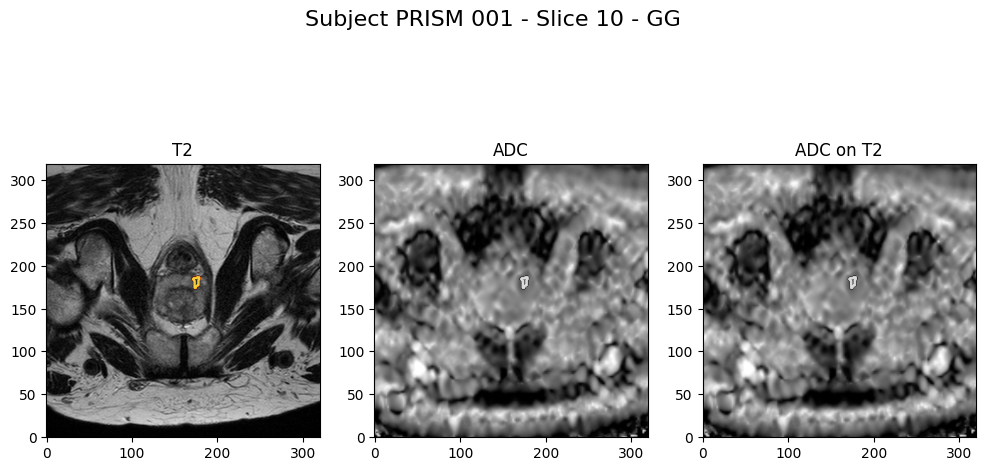

In [12]:
import os
os.environ["ITK_GLOBAL_DEFAULT_NUMBER_OF_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import ants
import numpy as np

MASK_THR = 0.5


def same_grid(a, b, atol_dir=1e-6, atol_org=1e-3, atol_sp=1e-6):
    return (
        tuple(a.shape) == tuple(b.shape) and
        np.allclose(a.spacing, b.spacing, atol=atol_sp) and
        np.allclose(a.origin, b.origin, atol=atol_org) and
        np.allclose(a.direction, b.direction, atol=atol_dir)
    )


def resample_to_target(moving, target, interp="linear"):
    return ants.resample_image_to_target(
        moving,
        target,
        interp_type="nearestNeighbor" if interp == "nearest" else "linear",
        imagetype=0 
    )


print("🚀 ADC -> T2 with geometry-only resampling")

for subj in SUBJS:
    try:
        #base = f"data/PRISM_UNIFIED/PRISM {subj}"
        out = f"data/{subj}"

        t2_path = f"{out}/images/0001.nii.gz"
        adc_path = f"{out}/images/0000.nii.gz"
        lesion_mask_path = f"{out}/labels/0001.nii.gz"

        out_adc = f"{out}/images/0000.nii.gz"
        out_mask = f"{out}/labels/0001.nii.gz"

        if not all(os.path.exists(p) for p in [t2_path, adc_path, lesion_mask_path]):
            print(f"[{subj}] ❌ missing files")
            continue

        t2 = ants.image_read(t2_path)
        adc = ants.image_read(adc_path)
        lesion_mask = ants.image_read(lesion_mask_path)

        # solo resample geometrico
        adc_on_t2 = resample_to_target(adc, t2, interp="linear")

        lesion_mask_on_t2 = resample_to_target(
            (lesion_mask > MASK_THR).astype("float32"),
            t2,
            interp="nearest"
        )

        ants.image_write(adc_on_t2, out_adc)
        ants.image_write(lesion_mask_on_t2, out_mask)

        print(
            f"[{subj}] ✅ saved | "
            f"adc_same_grid={same_grid(t2, adc_on_t2)} | "
            f"mask_same_grid={same_grid(t2, lesion_mask_on_t2)}"
        )

    except Exception as e:
        print(f"[{subj}] ❌ {e}")
        

    for I in range(nib.load(t2_path).get_fdata().shape[2]):
        
        if np.sum(nib.load(lesion_mask_path).get_fdata()[:,:,I].T) > 0:
                
                fig, ax = plt.subplots(1, 3, figsize=(12, 6))
                
                fig.suptitle(f"Subject {subj} - Slice {I} - GG ", fontsize=16)
                
                ax[0].imshow(nib.load(t2_path).get_fdata()[:,:,I].T, cmap='gray', origin='lower')
                ax[0].contour(nib.load(lesion_mask_path).get_fdata()[:,:,I].T, cmap='hot', alpha=0.5, origin='lower')
                ax[0].set_title('T2')


                ax[1].imshow(nib.load(out_adc).get_fdata()[:,:,I].T, cmap='gray', origin='lower')
                ax[1].contour(nib.load(out_mask).get_fdata()[:,:,I].T, cmap='gray', origin='lower')
                ax[1].set_title('ADC')

                ax[2].imshow(nib.load(out_adc).get_fdata()[:,:,I].T, cmap='gray', origin='lower')
                ax[2].contour(nib.load(out_mask).get_fdata()[:,:,I].T, cmap='gray', origin='lower')
                ax[2].set_title('ADC on T2')
                plt.show()
                plt.close()
